# HW1 — Harvard's Endowment
**FINM 36700: Portfolio and Risk Management**

This notebook contains the write-up, calculations, tables, and figures. Sections 2 and 3 answer all graded questions. Section 1 is the ungraded reading discussion. Sections 4–7 are optional EXTRA analyses.

**Sources and data vintage.** The assignment is the [course web-book case](https://markhendricks.github.io/finm-portfolio/case_studies/Harvard%27s%20Endowment.html), accessed October 3, 2026. The data is `multi_asset_etf_data.xlsx`, downloaded from the [official course Box folder](https://uchicago.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2), file ID 2003613248823. Its `data source` sheet identifies Yahoo Finance adjusted prices and an as-of date of July 31, 2026. The reading source is the supplied `HMC.pdf`, Luis Viceira, *The Harvard Management Company and Inflation–Protected Bonds*, HBS 9-201-053, revised February 15, 2007.

The current workbook has a `descriptions` sheet rather than the older `Info` sheet mentioned by the assignment. We use its full available monthly sample for graded questions. The EXTRA OOS exercises retain the assignment's specified dates. All reported means and volatilities are annualized arithmetic statistics, not compound annual growth rates. Sharpe ratios use excess returns. Short positions and borrowing are allowed in the empirical optimization, as the questions impose no position bounds.

**Run:** keep this notebook and the Excel file in the same folder, install the packages in `requirements.txt`, and select **Restart Kernel and Run All**. No online data fetch is needed.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from scipy.optimize import minimize

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
ANNUALIZATION = 12
TARGET_MONTHLY = 0.01
TIPS_BUMP_MONTHLY = 0.0012
ANALYSIS_END = None  # None uses the whole supplied workbook; e.g. '2025-12-31' restricts it.
DATA_FILE = Path('multi_asset_etf_data.xlsx')
assert DATA_FILE.exists(), 'Place the course Excel file beside this notebook.'
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
print('Data SHA256:', hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())

Python: 3.11.8
Data SHA256: 86d22f4940fc8558c9620b808e101d5c486eb802975dec6e3f4430953d664025


## Data preparation and conventions

We construct monthly excess returns as $x_{i,t}=r_{i,t}-r_{SHV,t}$ and check them against the supplied excess-return sheet. SHV is treated as the course's one-period risk-free proxy. Actual ETF returns are an approximation to that theoretical asset. QAI is excluded from the core ten-asset analysis.

The estimators are $\hat\mu=\operatorname{mean}(x_t)$ and $\hat\Sigma=\operatorname{cov}(x_t)$ with sample denominator $T-1$. Annual mean, volatility, and Sharpe are $12\hat\mu$, $\sqrt{12}\hat\sigma$, and $\sqrt{12}\hat\mu/\hat\sigma$. Returns are decimals: 0.01 means 1% monthly. The raw monthly series is never annualized.

In [2]:
descriptions = pd.read_excel(DATA_FILE, sheet_name='descriptions').set_index('ticker')
source_metadata = pd.read_excel(DATA_FILE, sheet_name='data source')
total_all = pd.read_excel(DATA_FILE, sheet_name='total returns', index_col=0)
supplied_excess = pd.read_excel(DATA_FILE, sheet_name='excess returns', index_col=0)
total_all.index = pd.to_datetime(total_all.index)
supplied_excess.index = pd.to_datetime(supplied_excess.index)
total_all = total_all.sort_index()
risky = total_all.columns.drop('SHV')
excess_all = total_all[risky].sub(total_all['SHV'], axis=0)
assert total_all.index.is_unique and total_all.index.is_monotonic_increasing
assert np.isfinite(total_all.to_numpy()).all()
assert total_all.index.to_period('M').equals(
    pd.period_range(total_all.index.min(), total_all.index.max(), freq='M'))
np.testing.assert_allclose(excess_all[supplied_excess.columns], supplied_excess,
                           atol=1e-12, rtol=1e-10)
X = excess_all.drop(columns='QAI').loc[:ANALYSIS_END].copy()
R = total_all[X.columns].loc[X.index]
assert X.shape[1] == 10 and not X.isna().any().any()
mu, cov = X.mean(), X.cov()
assert np.linalg.eigvalsh(cov).min() > 0

asset_classes = {
    'SPY': 'Domestic equity', 'EFA': 'Developed foreign equity',
    'EEM': 'Emerging-market equity', 'PSP': 'Listed private-equity proxy',
    'HYG': 'High-yield corporate bonds', 'DBC': 'Commodities',
    'IYR': 'Real estate', 'IEF': 'Domestic Treasury bonds',
    'BWX': 'Foreign government bonds', 'TIP': 'TIPS'
}
asset_info = pd.DataFrame({'Asset class': pd.Series(asset_classes),
                           'ETF name': descriptions['shortName']}).loc[X.columns]
display(asset_info)
display(Markdown(f'**Core sample:** {X.index.min():%Y-%m} to '
                 f'{X.index.max():%Y-%m}, **{len(X)} months**. '
                 f'Covariance condition number: {np.linalg.cond(cov):.1f}.'))
display(source_metadata.iloc[:7])

,Asset class,ETF name
BWX,Foreign government bonds,State Street SPDR Bloomberg Int
DBC,Commodities,Invesco DB Commodity Index Trac
EEM,Emerging-market equity,iShares MSCI Emerging Index Fun
EFA,Developed foreign equity,iShares MSCI EAFE ETF
HYG,High-yield corporate bonds,iShares iBoxx $ High Yield Corp
IEF,Domestic Treasury bonds,iShares 7-10 Year Treasury Bond
IYR,Real estate,iShares U.S. Real Estate ETF
PSP,Listed private-equity proxy,Invesco Global Listed Private E
SPY,Domestic equity,State Street SPDR S&P 500 ETF T
TIP,TIPS,iShares TIPS Bond ETF


**Core sample:** 2011-02 to 2026-07, **186 months**. Covariance condition number: 359.3.

,field,value
0,dataset,multi_asset_etf_data
1,source,Yahoo Finance via yahooquery
2,as_of,2026-07-31
3,retrieved_at_utc,2026-08-01 20:38:54.391000
4,frequency,monthly
5,field,adjusted close (adjclose); monthly total retur...
6,window,prices 2011-01-31 to 2026-07-31; returns 2011-...


PSP holds publicly listed private-equity businesses and is not a series of unlisted fund NAV returns. Likewise, ETF implementations differ from the original HMC benchmarks. We therefore interpret the exercise as an ETF-based illustration of allocation, rather than a replication of HMC's 2000 policy portfolio. The workbook records a correction to legacy SHV returns and a provider revision to HYG history; using a different data vintage can change results.

## 1. READING — HMC's approach (ungraded)

**1. Optimizing 1,000 securities.** A full covariance matrix has 500,500 distinct entries, in addition to 1,000 expected returns. With fewer return observations than assets, the sample covariance is singular. Even with a longer history, noisy means and correlations can produce unstable, extreme allocations. Computation is feasible on modern hardware; estimation error, changing exposures, and implementation constraints are the main obstacles.

**2. Two-stage optimization.** The within-class portfolios must preserve the opportunities that matter for the total portfolio. Securities within a class should have similar cross-class exposures, so class-level aggregation does not discard useful hedges. Low between-class correlation alone is not sufficient: with completely independent blocks, a fixed within-class tangency portfolio preserves the overall tangency direction, but arbitrary within-class portfolios need not. More generally, the globally optimal security weights must lie in the span of the retained class portfolios; otherwise fixing one portfolio per class can lose efficient combinations.

**3. A separate TIPS class.** TIPS have a contractual inflation adjustment and exposure to real interest rates. Nominal Treasury bonds have a different inflation exposure. These distinct risks support tracking TIPS separately, although TIPS ETF mark-to-market returns remain sensitive to real yields and duration. The empirical question is whether TIP adds a return component that cannot be replicated by the other available ETFs.

**4. Real versus nominal returns.** Harvard must support spending and preserve purchasing power. With inflation $\pi_t$, $1+r^{real}_{i,t}=(1+r^{nom}_{i,t})/(1+\pi_t)$. Random inflation changes means, variances, and covariance with liabilities and assets; it can change the optimizer. Only a deterministic common transformation preserves the ranking of feasible mean–variance portfolios. The core empirical task below uses nominal excess returns, as instructed.

**5. Position bounds.** Add $l_i\leq w_i\leq u_i$ to $\min_w w'\Sigma w$, subject to $\mathbf1'w=1$ and $\mu'w=\mu_{target}$. Include cash as an asset when reproducing the case's real-return model. Exhibit 5 permits risky weights from 0% to 100% and cash from −50% to 100%. Exhibit 6 uses the specified policy-centered bounds for other assets and 0%–100% for TIPS. These are quadratic programs with linear constraints.

**6. Binding lower bounds.** Under the assumed capital-market inputs, domestic equity and domestic nominal bonds do not offer enough marginal return relative to their covariance with the selected portfolio. Their reduced-gradient conditions place them at their 0% lower bounds over the stated target range. Removing those lower bounds permits negative allocations in the relevant unconstrained solutions, freeing capital for more attractive combinations. This is a portfolio-level conclusion, not a ranking based solely on standalone Sharpe ratios.

**7. Effect of tighter bounds.** HMC.pdf Exhibits 5 and 6 show that volatility rises from 5.87% to 6.46% at a 5.75% real mean, and from 9.88% to 10.61% at a 7.25% real mean. That is 0.59–0.73 percentage points at the two endpoints. Sharpe falls from about 0.38 to 0.35–0.36. The deterioration is modest at those common target means, although allocations change substantially. These original real-return numbers are distinct from the ETF calculations below.

## 2. Mean–variance optimization (graded)
### 2.1 Summary statistics

In [3]:
def annual_stats(returns):
    if isinstance(returns, pd.Series):
        returns = returns.to_frame(returns.name or 'Portfolio')
    mean = returns.mean() * ANNUALIZATION
    vol = returns.std(ddof=1) * np.sqrt(ANNUALIZATION)
    return pd.DataFrame({'Annual mean excess': mean, 'Annual volatility': vol,
                         'Annual Sharpe': mean / vol})

def show_stats(table):
    display(table.style.format({c: ('{:.4f}' if 'Sharpe' in c else '{:.2%}')
                                for c in table.columns}))

summary = annual_stats(X)
show_stats(summary.sort_values('Annual Sharpe', ascending=False))
best, worst = summary['Annual Sharpe'].idxmax(), summary['Annual Sharpe'].idxmin()
display(Markdown(f'**Answer:** {best} has the highest annual Sharpe '
    f'({summary.loc[best, "Annual Sharpe"]:.4f}); {worst} has the lowest '
    f'({summary.loc[worst, "Annual Sharpe"]:.4f}).'))
summary.to_csv(OUTPUT / 'asset_summary.csv')

,Annual mean excess,Annual volatility,Annual Sharpe
SPY,12.70%,14.14%,0.8979
HYG,3.45%,7.33%,0.4705
EFA,6.38%,14.86%,0.4291
IYR,7.01%,16.55%,0.4235
PSP,7.64%,21.13%,0.3617
TIP,1.28%,4.97%,0.2568
EEM,4.44%,17.91%,0.2481
IEF,0.86%,6.21%,0.1384
DBC,1.30%,17.23%,0.0755
BWX,-1.72%,8.19%,-0.2096


**Answer:** SPY has the highest annual Sharpe (0.8979); BWX has the lowest (-0.2096).

### 2.2 Correlations and the performance of TIPS

The main matrix uses the excess returns specified for this section. We also report the extreme pairs using total returns to make the convention explicit. Self-correlations and duplicate symmetric pairs are excluded.

,BWX,DBC,EEM,EFA,HYG,IEF,IYR,PSP,SPY,TIP
BWX,1.000,0.161,0.612,0.613,0.600,0.581,0.555,0.524,0.444,0.675
DBC,0.161,1.000,0.439,0.440,0.419,-0.309,0.253,0.420,0.384,0.084
EEM,0.612,0.439,1.000,0.812,0.670,0.051,0.574,0.697,0.693,0.384
EFA,0.613,0.440,0.812,1.000,0.776,0.063,0.700,0.862,0.833,0.402
HYG,0.600,0.419,0.670,0.776,1.000,0.193,0.731,0.798,0.783,0.540
IEF,0.581,-0.309,0.051,0.063,0.193,1.000,0.322,0.012,0.011,0.756
IYR,0.555,0.253,0.574,0.700,0.731,0.322,1.000,0.726,0.743,0.600
PSP,0.524,0.420,0.697,0.862,0.798,0.012,0.726,1.000,0.872,0.397
SPY,0.444,0.384,0.693,0.833,0.783,0.011,0.743,0.872,1.000,0.386
TIP,0.675,0.084,0.384,0.402,0.540,0.756,0.600,0.397,0.386,1.000


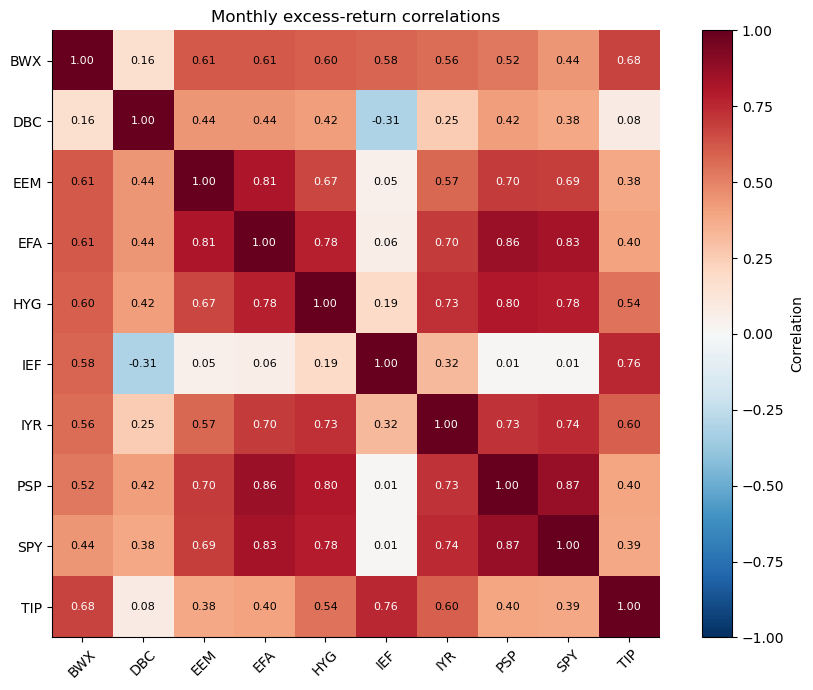

**Excess returns:** highest pair ('PSP', 'SPY') = 0.8722; lowest pair ('DBC', 'IEF') = -0.3088.

**Total returns:** highest pair ('PSP', 'SPY') = 0.8720; lowest pair ('DBC', 'IEF') = -0.3058.

,Annual mean excess,Annual volatility,Annual Sharpe
TIP,1.28%,4.97%,0.2568
IEF,0.86%,6.21%,0.1384
BWX,-1.72%,8.19%,-0.2096


TIP earns 1.28% annual excess return with 4.97% volatility and a 0.2568 Sharpe. In this sample, TIP exceeds both IEF and BWX in mean excess return and Sharpe, and has lower volatility than both. Its return is positive but modest relative to domestic equity. This comparison uses nominal realized ETF returns and does not measure the value of hedging Harvard's inflation-linked spending directly.

In [4]:
corr = X.corr()
def pair_correlations(data):
    c = data.corr()
    return c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values()

pairs = pair_correlations(X)
display(corr.style.format('{:.3f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j]) > .65 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Monthly excess-return correlations')
fig.tight_layout()
fig.savefig(OUTPUT / 'correlation.png', dpi=160)
plt.show()
raw_pairs = pair_correlations(R)
display(Markdown(f'**Excess returns:** highest pair {pairs.index[-1]} = {pairs.iloc[-1]:.4f}; '
    f'lowest pair {pairs.index[0]} = {pairs.iloc[0]:.4f}.\n\n'
    f'**Total returns:** highest pair {raw_pairs.index[-1]} = {raw_pairs.iloc[-1]:.4f}; '
    f'lowest pair {raw_pairs.index[0]} = {raw_pairs.iloc[0]:.4f}.'))
show_stats(summary.loc[['TIP', 'IEF', 'BWX']])
display(Markdown(f'TIP earns {summary.loc["TIP", "Annual mean excess"]:.2%} annual excess return '
    f'with {summary.loc["TIP", "Annual volatility"]:.2%} volatility and a '
    f'{summary.loc["TIP", "Annual Sharpe"]:.4f} Sharpe. '
    'In this sample, TIP exceeds both IEF and BWX in mean excess return and Sharpe, '
    'and has lower volatility than both. Its return is positive but modest relative to domestic equity. '
    'This comparison uses nominal realized ETF returns and does not measure the value of hedging '
    'Harvard\'s inflation-linked spending directly.'))
corr.to_csv(OUTPUT / 'correlations.csv')

### 2.3 Tangency portfolio

With a risk-free asset, the optimal risky direction is $d=\hat\Sigma^{-1}\hat\mu$. The unit-budget risky tangency portfolio is
$$w^{tan}=\frac{d}{\mathbf1'd}.$$
We solve the linear system rather than explicitly invert the covariance matrix. The sign of $\mathbf1'd$ must be checked: a negative denominator produces a negative-mean, inefficient unit-budget tangency portfolio. The optimal positive-return direction still follows $d$.

In [5]:
def direction(mean, covariance):
    return pd.Series(np.linalg.solve(covariance.to_numpy(), mean.to_numpy()), index=mean.index)

def tangency(mean, covariance):
    d = direction(mean, covariance)
    if abs(d.sum()) < 1e-12:
        raise ValueError('Unit-budget tangency is undefined: direction sums to zero.')
    return d / d.sum()

def model_stats(weights, mean, covariance):
    annual_mean = float(weights @ mean) * ANNUALIZATION
    annual_vol = np.sqrt(float(weights @ covariance @ weights) * ANNUALIZATION)
    return pd.Series({'Annual mean excess': annual_mean, 'Annual volatility': annual_vol,
                      'Annual Sharpe': annual_mean / annual_vol})

w_tan = tangency(mu, cov)
tan_stats = model_stats(w_tan, mu, cov)
rank_comparison = pd.DataFrame({'Tangency weight': w_tan,
    'Weight rank': w_tan.rank(ascending=False).astype(int),
    'Standalone Sharpe': summary['Annual Sharpe'],
    'Sharpe rank': summary['Annual Sharpe'].rank(ascending=False).astype(int)})
display(rank_comparison.sort_values('Tangency weight', ascending=False).style.format(
    {'Tangency weight': '{:.2%}', 'Standalone Sharpe': '{:.4f}'}))
show_stats(tan_stats.to_frame('Tangency').T)
np.testing.assert_allclose(w_tan.sum(), 1, atol=1e-12)
np.testing.assert_allclose(annual_stats((X @ w_tan).rename('Tangency')).iloc[0], tan_stats)
display(Markdown(f'**Answer:** the rankings differ. IEF has a low standalone Sharpe '
    f'({summary.loc["IEF", "Annual Sharpe"]:.4f}) but the largest positive tangency weight '
    f'({w_tan["IEF"]:.2%}); TIP has a positive standalone Sharpe but a '
    f'{w_tan["TIP"]:.2%} tangency weight. Weights depend on the entire covariance matrix '
    'and each asset\'s incremental contribution after hedging the other assets. '
    'A negative mean asset can enter as a short position. '
    f'The tangency portfolio has mean {tan_stats.iloc[0]:.2%}, volatility '
    f'{tan_stats.iloc[1]:.2%}, and Sharpe {tan_stats.iloc[2]:.4f}. '
    f'Its gross risky exposure is {w_tan.abs().sum():.2f} times capital, '
    'so the unconstrained result involves substantial long and short positions.'))
rank_comparison.to_csv(OUTPUT / 'tangency_weights.csv')

,Tangency weight,Weight rank,Standalone Sharpe,Sharpe rank
IEF,131.88%,1,0.1384,8
SPY,126.32%,2,0.8979,1
HYG,20.38%,3,0.4705,2
EFA,18.48%,4,0.4291,3
DBC,3.63%,5,0.0755,9
EEM,-0.10%,6,0.2481,7
TIP,-19.20%,7,0.2568,6
IYR,-22.37%,8,0.4235,4
PSP,-41.06%,9,0.3617,5
BWX,-117.97%,10,-0.2096,10


,Annual mean excess,Annual volatility,Annual Sharpe
Tangency,16.17%,10.96%,1.4758


**Answer:** the rankings differ. IEF has a low standalone Sharpe (0.1384) but the largest positive tangency weight (131.88%); TIP has a positive standalone Sharpe but a -19.20% tangency weight. Weights depend on the entire covariance matrix and each asset's incremental contribution after hedging the other assets. A negative mean asset can enter as a short position. The tangency portfolio has mean 16.17%, volatility 10.96%, and Sharpe 1.4758. Its gross risky exposure is 5.01 times capital, so the unconstrained result involves substantial long and short positions.

### 2.4 Does TIPS expand the opportunity set?

We compare the full universe, the universe without TIP, and a scenario that increases only TIP's expected **monthly** excess return by 0.0012 (12 bp, or 1.44 percentage points annualized). Covariances stay fixed. For the last scenario, model-implied performance uses the adjusted mean; historical realized performance evaluates its new weights on the unchanged original returns. Adding a constant to every TIP return would be an equivalent way to compute the hypothetical model moments, but would not be a new realized dataset.

In [6]:
mu_no_tip = mu.drop('TIP')
cov_no_tip = cov.loc[mu_no_tip.index, mu_no_tip.index]
w_no_tip = tangency(mu_no_tip, cov_no_tip)
mu_bump = mu.copy()
mu_bump['TIP'] += TIPS_BUMP_MONTHLY
w_bump = tangency(mu_bump, cov)
scenario_weights = pd.DataFrame({'Baseline': w_tan,
    'Without TIP': w_no_tip.reindex(mu.index, fill_value=0),
    'TIP mean +12 bp/month': w_bump})
scenario_weights['Change: no TIP'] = scenario_weights['Without TIP'] - w_tan
scenario_weights['Change: higher TIP mean'] = w_bump - w_tan
display(scenario_weights.style.format('{:.2%}'))
scenario_stats = pd.DataFrame({
    'Baseline': model_stats(w_tan, mu, cov),
    'Without TIP': model_stats(w_no_tip, mu_no_tip, cov_no_tip),
    'Higher TIP mean: adjusted model': model_stats(w_bump, mu_bump, cov),
    'Higher TIP mean: original history': model_stats(w_bump, mu, cov)
}).T
show_stats(scenario_stats)

# A common 1% monthly target removes differences in tangency normalization.
def target_scale(weights, mean, target=TARGET_MONTHLY):
    denominator = float(weights @ mean)
    if abs(denominator) < 1e-12:
        raise ValueError('Cannot scale a zero-mean direction to a positive target.')
    return weights * target / denominator

target_comparison = pd.DataFrame({
    'Baseline': model_stats(target_scale(w_tan, mu), mu, cov),
    'Without TIP': model_stats(target_scale(w_no_tip, mu_no_tip), mu_no_tip, cov_no_tip),
    'Higher TIP mean: adjusted model': model_stats(target_scale(w_bump, mu_bump), mu_bump, cov)
}).T
show_stats(target_comparison)
sr_base = scenario_stats.loc['Baseline', 'Annual Sharpe']
sr_no = scenario_stats.loc['Without TIP', 'Annual Sharpe']
sr_bump = scenario_stats.loc['Higher TIP mean: adjusted model', 'Annual Sharpe']
display(Markdown(f'**Answer:** removing TIP changes its risky weight from '
    f'{w_tan["TIP"]:.2%} to zero and changes maximum positive Sharpe from '
    f'{sr_base:.4f} to {sr_no:.4f} (a decrease of {sr_base-sr_no:.4f}). '
    f'Increasing its expected return changes the TIP weight to {w_bump["TIP"]:.2%} '
    f'and the adjusted-model Sharpe to {sr_bump:.4f}. '
    'The common-target table measures the volatility effect without confounding it with different '
    'unit-budget tangency means. TIP strictly expands the estimated feasible opportunity set, '
    'but the baseline Sharpe improvement is small. The large weight reversal after a relatively '
    'small mean adjustment illustrates sensitivity to expected-return estimates. '
    'This supports monitoring TIPS as a distinct inflation and real-rate exposure, while avoiding '
    'the claim that historical nominal ETF moments alone establish a large optimal long allocation. '
    'The adjusted-model improvement is a scenario result, not an observed investment gain.'))
scenario_weights.to_csv(OUTPUT / 'tips_scenario_weights.csv')
scenario_stats.to_csv(OUTPUT / 'tips_scenario_performance.csv')

,Baseline,Without TIP,TIP mean +12 bp/month,Change: no TIP,Change: higher TIP mean
BWX,-117.97%,-113.75%,-86.02%,4.22%,31.95%
DBC,3.63%,2.58%,-4.33%,-1.05%,-7.96%
EEM,-0.10%,-0.62%,-4.02%,-0.52%,-3.92%
EFA,18.48%,18.81%,20.94%,0.32%,2.45%
HYG,20.38%,17.91%,1.72%,-2.46%,-18.66%
IEF,131.88%,116.16%,12.89%,-15.72%,-118.99%
IYR,-22.37%,-22.34%,-22.16%,0.03%,0.21%
PSP,-41.06%,-40.04%,-33.38%,1.01%,7.68%
SPY,126.32%,121.28%,88.19%,-5.04%,-38.13%
TIP,-19.20%,0.00%,126.17%,19.20%,145.37%


,Annual mean excess,Annual volatility,Annual Sharpe
Baseline,16.17%,10.96%,1.4758
Without TIP,15.54%,10.54%,1.4745
Higher TIP mean: adjusted model,13.27%,8.42%,1.5749
Higher TIP mean: original history,11.45%,8.42%,1.3592


,Annual mean excess,Annual volatility,Annual Sharpe
Baseline,12.00%,8.13%,1.4758
Without TIP,12.00%,8.14%,1.4745
Higher TIP mean: adjusted model,12.00%,7.62%,1.5749


**Answer:** removing TIP changes its risky weight from -19.20% to zero and changes maximum positive Sharpe from 1.4758 to 1.4745 (a decrease of 0.0012). Increasing its expected return changes the TIP weight to 126.17% and the adjusted-model Sharpe to 1.5749. The common-target table measures the volatility effect without confounding it with different unit-budget tangency means. TIP strictly expands the estimated feasible opportunity set, but the baseline Sharpe improvement is small. The large weight reversal after a relatively small mean adjustment illustrates sensitivity to expected-return estimates. This supports monitoring TIPS as a distinct inflation and real-rate exposure, while avoiding the claim that historical nominal ETF moments alone establish a large optimal long allocation. The adjusted-model improvement is a scenario result, not an observed investment gain.

The following plot displays the risky-only minimum-variance frontier in excess-return coordinates, together with the positive capital-allocation line when the risk-free asset is available. It is supplementary to the requested tangency calculation.

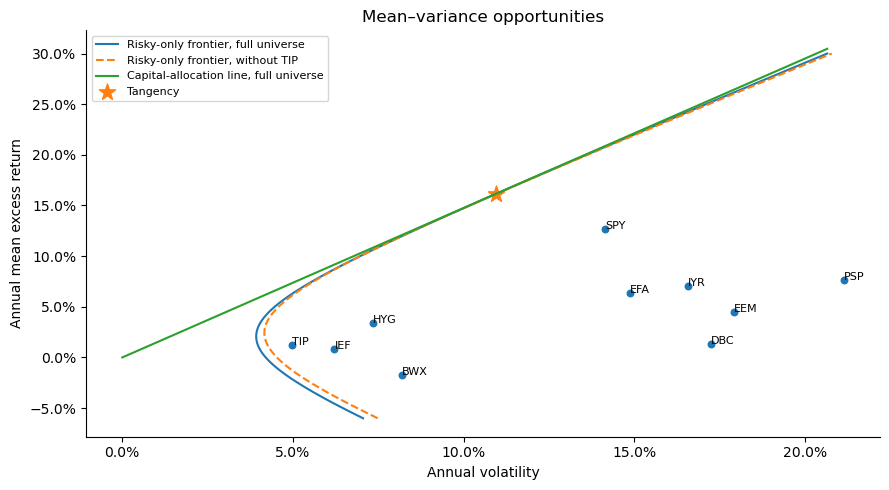

In [7]:
def risky_frontier(mean, covariance, targets):
    one = np.ones(len(mean))
    inv_one = np.linalg.solve(covariance, one)
    inv_mu = np.linalg.solve(covariance, mean)
    A, B, C = one @ inv_one, one @ inv_mu, mean @ inv_mu
    D = A*C - B*B
    if D <= 0:
        raise ValueError('Degenerate risky frontier.')
    weights = np.column_stack([
        ((C-B*t)/D)*inv_one + ((A*t-B)/D)*inv_mu for t in targets])
    vols = np.sqrt(np.einsum('ik,ij,jk->k', weights, covariance, weights)*12)
    return weights, vols

target_grid = np.linspace(-.005, .025, 200)
_, frontier_vol = risky_frontier(mu, cov, target_grid)
fig, ax = plt.subplots()
ax.plot(frontier_vol, 12*target_grid, label='Risky-only frontier, full universe')
_, no_vol = risky_frontier(mu_no_tip, cov_no_tip, target_grid)
ax.plot(no_vol, 12*target_grid, ls='--', label='Risky-only frontier, without TIP')
line_vol = np.linspace(0, max(frontier_vol), 100)
ax.plot(line_vol, sr_base*line_vol, label='Capital-allocation line, full universe')
ax.scatter(summary['Annual volatility'], summary['Annual mean excess'], s=22)
for ticker, row in summary.iterrows():
    ax.annotate(ticker, (row.iloc[1], row.iloc[0]), fontsize=8)
ax.scatter([tan_stats.iloc[1]], [tan_stats.iloc[0]], marker='*', s=150, label='Tangency')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Annual volatility', ylabel='Annual mean excess return', title='Mean–variance opportunities')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / 'frontier.png', dpi=160)
plt.show()

## 3. Allocations (graded)

All methods target a monthly mean excess return of 1% (12% annualized). For any raw direction $a$, use $w=\mu_{target}a/(a'\hat\mu)$. EW starts with $a_i=1/n$. The assignment's “risk parity” uses **inverse variance**, $a_i=1/\hat\sigma_i^2$, rather than inverse volatility or equal risk contributions. MV uses $a=\hat\Sigma^{-1}\hat\mu$.

The scaled risky weights need not sum to one. The residual cash allocation is $1-\mathbf1'w$, so portfolio total return is $r_{SHV,t}+w'x_t$. Borrowing and lending are assumed to take place at the same SHV proxy rate. We report excess-return statistics for a consistent comparison.

In [8]:
def allocation_weights(data, target=TARGET_MONTHLY, include_reg=False):
    mean, covariance = data.mean(), data.cov()
    raw = {
        'EW': pd.Series(1/len(mean), index=mean.index),
        'RP': 1/pd.Series(np.diag(covariance), index=mean.index),
        'MV': direction(mean, covariance)
    }
    if include_reg:
        diagonal = pd.DataFrame(np.diag(np.diag(covariance)), index=mean.index, columns=mean.index)
        regularized = (covariance + diagonal)/2
        raw['REG'] = direction(mean, regularized)
    return pd.DataFrame({name: target_scale(a, mean, target) for name, a in raw.items()})

weights_core = allocation_weights(X)
returns_core = X @ weights_core
stats_core = annual_stats(returns_core)
display(weights_core.style.format('{:.2%}'))
exposure_core = pd.DataFrame({'Net risky weight': weights_core.sum(),
    'Residual SHV weight': 1-weights_core.sum(),
    'Gross risky exposure': weights_core.abs().sum()})
display(exposure_core.style.format('{:.2%}'))
show_stats(stats_core)
np.testing.assert_allclose(returns_core.mean(), TARGET_MONTHLY, atol=1e-12)
display(Markdown(f'**Answer:** all three methods achieve 12% annual mean excess return. '
    f'MV has volatility {stats_core.loc["MV", "Annual volatility"]:.2%} and Sharpe '
    f'{stats_core.loc["MV", "Annual Sharpe"]:.4f}; EW has volatility '
    f'{stats_core.loc["EW", "Annual volatility"]:.2%} and Sharpe '
    f'{stats_core.loc["EW", "Annual Sharpe"]:.4f}; RP has volatility '
    f'{stats_core.loc["RP", "Annual volatility"]:.2%} and Sharpe '
    f'{stats_core.loc["RP", "Annual Sharpe"]:.4f}. '
    'MV therefore has the lowest in-sample variance and highest Sharpe at this common target, '
    'as it is optimized on these same estimated moments. The inverse-variance RP rule emphasizes '
    'low-volatility bond ETFs, whose low mean excess returns require more leverage to reach the target. '
    'Neither the in-sample MV advantage nor the risk-parity label establishes superior future performance.'))
weights_core.to_csv(OUTPUT / 'allocation_weights.csv')
stats_core.to_csv(OUTPUT / 'allocation_performance.csv')

,EW,RP,MV
BWX,27.69%,67.33%,-87.56%
DBC,27.69%,15.21%,2.69%
EEM,27.69%,14.08%,-0.07%
EFA,27.69%,20.45%,13.72%
HYG,27.69%,83.97%,15.13%
IEF,27.69%,117.00%,97.88%
IYR,27.69%,16.48%,-16.60%
PSP,27.69%,10.11%,-30.47%
SPY,27.69%,22.58%,93.75%
TIP,27.69%,182.44%,-14.25%


,Net risky weight,Residual SHV weight,Gross risky exposure
EW,276.90%,-176.90%,276.90%
RP,549.66%,-449.66%,549.66%
MV,74.22%,25.78%,372.13%


,Annual mean excess,Annual volatility,Annual Sharpe
EW,12.00%,27.53%,0.4359
RP,12.00%,32.61%,0.3679
MV,12.00%,8.13%,1.4758


**Answer:** all three methods achieve 12% annual mean excess return. MV has volatility 8.13% and Sharpe 1.4758; EW has volatility 27.53% and Sharpe 0.4359; RP has volatility 32.61% and Sharpe 0.3679. MV therefore has the lowest in-sample variance and highest Sharpe at this common target, as it is optimized on these same estimated moments. The inverse-variance RP rule emphasizes low-volatility bond ETFs, whose low mean excess returns require more leverage to reach the target. Neither the in-sample MV advantage nor the risk-parity label establishes superior future performance.

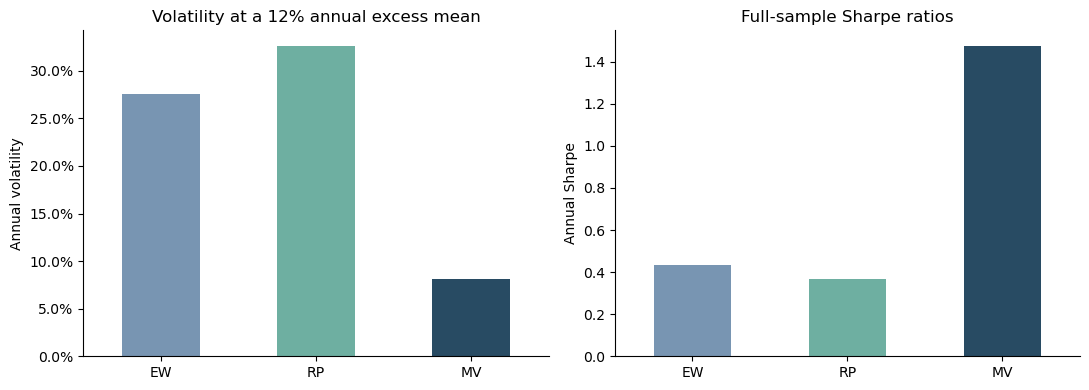

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats_core['Annual volatility'].plot.bar(ax=axes[0], color=['#7895b2','#6eafa1','#284b63'], rot=0)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title='Volatility at a 12% annual excess mean', ylabel='Annual volatility')
stats_core['Annual Sharpe'].plot.bar(ax=axes[1], color=['#7895b2','#6eafa1','#284b63'], rot=0)
axes[1].set(title='Full-sample Sharpe ratios', ylabel='Annual Sharpe')
fig.tight_layout()
fig.savefig(OUTPUT / 'allocation_comparison.png', dpi=160)
plt.show()

## 4. EXTRA — Out-of-sample performance (optional)
### 4.1 One-step OOS

Estimate and scale weights using data through December 2023. Hold those weights fixed during January 2024–December 2025. Data from 2026 is excluded from this exercise. REG is added here for comparison and formally defined in Section 6.

In [10]:
train = excess_all.drop(columns='QAI').loc[:'2023-12-31']
test = excess_all.drop(columns='QAI').loc['2024-01-01':'2025-12-31']
assert len(test) == 24 and train.index.max() < test.index.min()
weights_is = allocation_weights(train, include_reg=True)
one_step = pd.concat({'In sample, through 2023': annual_stats(train @ weights_is),
                      'Out of sample, 2024–2025': annual_stats(test @ weights_is)}, names=['Period','Method'])
display(weights_is.style.format('{:.2%}'))
show_stats(one_step)
display(Markdown('The 1% monthly target is imposed using training means only. OOS means are free to '
    'differ from the target; resetting weights using test-period means would introduce look-ahead bias. '
    'The fixed training-period optimizer need not dominate simpler rules in a new period.'))
one_step.to_csv(OUTPUT / 'extra_one_step_oos.csv')

,EW,RP,MV,REG
BWX,29.73%,68.17%,-86.89%,-71.52%
DBC,29.73%,15.19%,-1.01%,-12.99%
EEM,29.73%,13.47%,5.11%,-10.16%
EFA,29.73%,18.78%,-14.09%,2.92%
HYG,29.73%,72.26%,15.28%,32.00%
IEF,29.73%,112.85%,103.87%,43.49%
IYR,29.73%,15.63%,-19.91%,8.47%
PSP,29.73%,9.37%,-21.70%,4.15%
SPY,29.73%,21.34%,107.77%,63.21%
TIP,29.73%,167.53%,-10.61%,35.69%


The 1% monthly target is imposed using training means only. OOS means are free to differ from the target; resetting weights using test-period means would introduce look-ahead bias. The fixed training-period optimizer need not dominate simpler rules in a new period.

### 4.2 Expanding-window OOS

The assignment calls this rolling OOS but specifies using all observations **through** each year-end, so this is an expanding estimation window. We train through 2015 and test in 2016, then step forward annually through the 2022/2023 split. As explicitly stated by the question, the final weights trained through 2023 are held over **both 2024 and 2025**; there is no additional end-2024 refit. Statistics are computed on the concatenated realized monthly OOS returns, not averages of annual Sharpe ratios.

In [11]:
extra_data = excess_all.drop(columns='QAI').loc[:'2025-12-31']
oos_parts, schedule = [], []
for train_year in range(2015, 2024):
    train_end = pd.Timestamp(f'{train_year}-12-31')
    test_end_year = 2025 if train_year == 2023 else train_year+1
    estimation = extra_data.loc[:train_end]
    evaluation = extra_data.loc[f'{train_year+1}-01-01':f'{test_end_year}-12-31']
    w = allocation_weights(estimation, include_reg=True)
    assert estimation.index.max() < evaluation.index.min()
    np.testing.assert_allclose(estimation.mean() @ w, TARGET_MONTHLY, atol=1e-12)
    oos_parts.append(evaluation @ w)
    schedule.append({'Training through': train_year, 'First OOS month': evaluation.index.min(),
                     'Last OOS month': evaluation.index.max(), 'OOS months': len(evaluation)})
rolling_returns = pd.concat(oos_parts).sort_index()
assert rolling_returns.index.is_unique and len(rolling_returns) == 120
display(pd.DataFrame(schedule))
rolling_stats = annual_stats(rolling_returns)
show_stats(rolling_stats)
display(Markdown(f'The highest OOS Sharpe in this specified strategy is '
    f'**{rolling_stats["Annual Sharpe"].idxmax()}** '
    f'({rolling_stats["Annual Sharpe"].max():.4f}). '
    'These are frictionless outcomes; shorting costs, financing spreads, and rebalancing costs are omitted.'))
rolling_stats.to_csv(OUTPUT / 'extra_expanding_oos.csv')
rolling_returns.to_csv(OUTPUT / 'extra_expanding_oos_monthly.csv')

,Training through,First OOS month,Last OOS month,OOS months
0,2015,2016-01-31,2016-12-31,12
1,2016,2017-01-31,2017-12-31,12
2,2017,2018-01-31,2018-12-31,12
3,2018,2019-01-31,2019-12-31,12
4,2019,2020-01-31,2020-12-31,12
5,2020,2021-01-31,2021-12-31,12
6,2021,2022-01-31,2022-12-31,12
7,2022,2023-01-31,2023-12-31,12
8,2023,2024-01-31,2025-12-31,24


,Annual mean excess,Annual volatility,Annual Sharpe
EW,18.26%,29.37%,0.6215
RP,8.57%,25.92%,0.3306
MV,7.45%,9.56%,0.7799
REG,6.41%,10.76%,0.5960


The highest OOS Sharpe in this specified strategy is **MV** (0.7799). These are frictionless outcomes; shorting costs, financing spreads, and rebalancing costs are omitted.

## 5. EXTRA — Without a riskless asset (optional)

We now use **total returns** of the same ten risky ETFs, excluding both SHV and QAI. With no cash financing, $\mathbf1'w=1$ must hold. For a target monthly total mean $m$, define $A=\mathbf1'\Sigma^{-1}\mathbf1$, $B=\mathbf1'\Sigma^{-1}\mu$, $C=\mu'\Sigma^{-1}\mu$, and $D=AC-B^2$. Then
$$w(m)=\frac{C-Bm}{D}\Sigma^{-1}\mathbf1+\frac{Am-B}{D}\Sigma^{-1}\mu.$$
The weights are affine in $m$; frontier volatility is nonlinear in $m$. This two-fund formula satisfies both constraints. We retain total-mean and volatility units and label mean/volatility as such; without a specified benchmark it should not be called an excess-return Sharpe.

In [12]:
mu_total, cov_total = R.mean(), R.cov()
total_target = .01
w_total_array, _ = risky_frontier(mu_total, cov_total, [total_target])
w_total = pd.Series(w_total_array[:,0], index=R.columns)
one = np.ones(len(mu_total))
inv_one = np.linalg.solve(cov_total, one)
w_gmv = pd.Series(inv_one/(one @ inv_one), index=R.columns)
display(pd.DataFrame({'Global minimum variance': w_gmv,
    'Target 1% monthly total mean': w_total}).style.format('{:.2%}'))
no_rf_stats = annual_stats(pd.DataFrame({'GMV': R @ w_gmv,
                                       'Target 1% total/month': R @ w_total})).rename(
    columns={'Annual mean excess': 'Annual mean total', 'Annual Sharpe': 'Annual mean/volatility'})
display(no_rf_stats.style.format({'Annual mean total':'{:.2%}', 'Annual volatility':'{:.2%}',
                                  'Annual mean/volatility':'{:.4f}'}))
np.testing.assert_allclose(w_total.sum(), 1, atol=1e-12)
np.testing.assert_allclose(w_total @ mu_total, total_target, atol=1e-12)

# Revisit the two TIP scenarios at the same total-return target.
total_scenarios = {'Baseline': (mu_total, cov_total),
    'Without TIP': (mu_total.drop('TIP'), cov_total.drop(index='TIP',columns='TIP'))}
total_bump = mu_total.copy()
total_bump['TIP'] += TIPS_BUMP_MONTHLY
total_scenarios['Higher TIP mean'] = (total_bump, cov_total)
weights_without_rf, rows_without_rf = {}, {}
for name, (m, s) in total_scenarios.items():
    ws, _ = risky_frontier(m, s, [total_target])
    weights = pd.Series(ws[:,0], index=m.index)
    weights_without_rf[name] = weights.reindex(mu_total.index, fill_value=0)
    result = model_stats(weights, m, s)
    rows_without_rf[name] = result.rename({'Annual mean excess':'Annual mean total',
                                          'Annual Sharpe':'Annual mean/volatility'})
    np.testing.assert_allclose([weights.sum(), weights @ m], [1,total_target], atol=1e-12)
display(pd.DataFrame(weights_without_rf).style.format('{:.2%}'))
display(pd.DataFrame(rows_without_rf).T.style.format({'Annual mean total':'{:.2%}',
    'Annual volatility':'{:.2%}', 'Annual mean/volatility':'{:.4f}'}))
display(Markdown('The bond-heavy GMV portfolio replaces cash as the low-risk reference fund. '
    'TIP remains useful as a separate instrument: deleting it restricts feasible combinations, '
    'and increasing its expected return changes its allocation. '
    'The 1% total-return target here is distinct from the 1% excess-return target in Section 3.'))

,Global minimum variance,Target 1% monthly total mean
BWX,-8.96%,-74.58%
DBC,6.54%,4.86%
EEM,-4.82%,-2.18%
EFA,4.64%,12.65%
HYG,36.23%,26.85%
IEF,22.79%,86.96%
IYR,-16.97%,-19.98%
PSP,-9.72%,-28.34%
SPY,11.85%,80.24%
TIP,58.43%,13.52%


,Annual mean total,Annual volatility,Annual mean/volatility
GMV,3.56%,3.96%,0.8999
Target 1% total/month,12.00%,7.29%,1.6457


,Baseline,Without TIP,Higher TIP mean
BWX,-74.58%,-74.04%,-65.75%
DBC,4.86%,5.86%,-1.34%
EEM,-2.18%,-1.91%,-4.47%
EFA,12.65%,11.87%,16.22%
HYG,26.85%,29.54%,11.13%
IEF,86.96%,96.31%,14.19%
IYR,-19.98%,-19.81%,-20.49%
PSP,-28.34%,-28.03%,-26.84%
SPY,80.24%,80.22%,67.50%
TIP,13.52%,0.00%,109.84%


,Annual mean total,Annual volatility,Annual mean/volatility
Baseline,12.00%,7.29%,1.6457
Without TIP,12.00%,7.30%,1.6439
Higher TIP mean,12.00%,6.74%,1.7814


The bond-heavy GMV portfolio replaces cash as the low-risk reference fund. TIP remains useful as a separate instrument: deleting it restricts feasible combinations, and increasing its expected return changes its allocation. The 1% total-return target here is distinct from the 1% excess-return target in Section 3.

## 6. EXTRA — Regularized allocation (optional)

Set $\hat\Sigma_{REG}=\tfrac12(\hat\Sigma+\hat\Sigma_D)$, where $\hat\Sigma_D$ contains only the original diagonal variances. Thus variances are unchanged and off-diagonal covariances are halved. Use $\hat\Sigma_{REG}^{-1}\hat\mu$ and scale to the same 1% monthly excess target. Performance is evaluated on **actual sample returns / original covariance**, not the artificially shrunk covariance. This is a covariance-shrinkage rule, not a fully specified Bayesian posterior model.

In [13]:
weights_reg = allocation_weights(X, include_reg=True)
stats_reg = annual_stats(X @ weights_reg)
display(weights_reg.style.format('{:.2%}'))
show_stats(stats_reg)
reg_cov = .5*(cov + pd.DataFrame(np.diag(np.diag(cov)), index=cov.index, columns=cov.columns))
np.testing.assert_allclose(np.diag(reg_cov), np.diag(cov))
np.testing.assert_allclose((X @ weights_reg).mean(), TARGET_MONTHLY, atol=1e-12)
display(Markdown('REG reduces reliance on precisely estimated cross-asset hedges. Its in-sample '
    'Sharpe cannot exceed the unconstrained MV maximum when both use the same actual moments. '
    'Its possible benefit is more stable estimated allocations and better future performance, '
    'which is assessed in Section 4 rather than presumed.'))
stats_reg.to_csv(OUTPUT / 'extra_regularized_performance.csv')

,EW,RP,MV,REG
BWX,27.69%,67.33%,-87.56%,-78.68%
DBC,27.69%,15.21%,2.69%,-5.51%
EEM,27.69%,14.08%,-0.07%,-1.17%
EFA,27.69%,20.45%,13.72%,10.90%
HYG,27.69%,83.97%,15.13%,29.56%
IEF,27.69%,117.00%,97.88%,36.08%
IYR,27.69%,16.48%,-16.60%,6.62%
PSP,27.69%,10.11%,-30.47%,-2.03%
SPY,27.69%,22.58%,93.75%,64.09%
TIP,27.69%,182.44%,-14.25%,23.75%


,Annual mean excess,Annual volatility,Annual Sharpe
EW,12.00%,27.53%,0.4359
RP,12.00%,32.61%,0.3679
MV,12.00%,8.13%,1.4758
REG,12.00%,10.51%,1.1413


REG reduces reliance on precisely estimated cross-asset hedges. Its in-sample Sharpe cannot exceed the unconstrained MV maximum when both use the same actual moments. Its possible benefit is more stable estimated allocations and better future performance, which is assessed in Section 4 rather than presumed.

## 7. EXTRA — Include QAI and check inefficient tangency (optional)

Include QAI, construct $d=\Sigma^{-1}\mu$ and normalize it to unit risky budget. If $\mathbf1'd<0$, the normalized tangency portfolio has negative mean and signed Sharpe. Shorting that portfolio gives the efficient positive-return direction. Its risky weights then sum to −1, with cash 2 to preserve total capital. Regardless of the normalization sign, scaling $d$ to a positive target gives the optimal feasible allocation. We check the sign from this data vintage rather than assume the older sample's outcome.

In [14]:
X_qai = excess_all.loc[X.index]
mu_qai, cov_qai = X_qai.mean(), X_qai.cov()
w_qai_tan = tangency(mu_qai, cov_qai)
qai_tan_stat = model_stats(w_qai_tan, mu_qai, cov_qai)
efficient_sign = 1 if qai_tan_stat['Annual mean excess'] >= 0 else -1
w_qai_efficient = efficient_sign * w_qai_tan
show_stats(pd.DataFrame({'Unit-budget tangency': qai_tan_stat,
    'Positive-return direction': model_stats(w_qai_efficient, mu_qai, cov_qai)}).T)
display(pd.DataFrame({'Unit-budget tangency': w_qai_tan,
                      'Positive-return direction': w_qai_efficient}).style.format('{:.2%}'))
weights_qai = allocation_weights(X_qai, include_reg=True)
qai_stats = annual_stats(X_qai @ weights_qai)
show_stats(qai_stats)
comparison_qai = pd.concat({'Without QAI': stats_reg, 'With QAI': qai_stats}, names=['Universe','Method'])
show_stats(comparison_qai)
delta_qai = qai_stats.loc['MV','Annual Sharpe'] - stats_reg.loc['MV','Annual Sharpe']
display(Markdown(f'For this workbook, the unit-budget tangency annual mean is '
    f'{qai_tan_stat["Annual mean excess"]:.2%}, so '
    + ('shorting it is required to obtain the positive-return direction. ' if efficient_sign == -1
       else 'the unit-budget tangency already lies in the positive-return direction. ')
    + f'Including QAI changes optimal MV Sharpe by {delta_qai:.4f}. '
    'An enlarged unconstrained investment universe cannot reduce the maximum positive Sharpe '
    'on identical dates, because assigning QAI zero weight recovers the old feasible set. '
    'EW and inverse-variance RP do not obey the same monotonicity property.'))
comparison_qai.to_csv(OUTPUT / 'extra_qai_comparison.csv')

,Annual mean excess,Annual volatility,Annual Sharpe
Unit-budget tangency,-98.88%,62.00%,-1.5950
Positive-return direction,98.88%,62.00%,1.5950


,Unit-budget tangency,Positive-return direction
BWX,594.31%,-594.31%
DBC,-47.45%,47.45%
EEM,-95.97%,95.97%
EFA,-122.71%,122.71%
HYG,-129.34%,129.34%
IEF,-872.25%,872.25%
IYR,140.25%,-140.25%
PSP,191.40%,-191.40%
QAI,1236.34%,-1236.34%
SPY,-888.03%,888.03%


,Annual mean excess,Annual volatility,Annual Sharpe
EW,12.00%,27.59%,0.4350
RP,12.00%,31.41%,0.3821
MV,12.00%,7.52%,1.5950
REG,12.00%,10.52%,1.1408


For this workbook, the unit-budget tangency annual mean is -98.88%, so shorting it is required to obtain the positive-return direction. Including QAI changes optimal MV Sharpe by 0.1192. An enlarged unconstrained investment universe cannot reduce the maximum positive Sharpe on identical dates, because assigning QAI zero weight recovers the old feasible set. EW and inverse-variance RP do not obey the same monotonicity property.

## Verification and interpretation

The following checks verify financing, target means, and the optimization using an independent constrained numerical solution. Reported empirical results are in-sample except where explicitly labeled OOS. The analysis omits position limits, transaction costs, funding spreads, and liability matching; these assumptions explain why the empirical allocations can differ markedly from HMC's bounded policy portfolio.

In [15]:
# Independent SLSQP solve: variance minimization at the same monthly excess target.
objective = lambda w: float(w @ cov.to_numpy() @ w) * 1e4
jacobian = lambda w: 2 * cov.to_numpy() @ w * 1e4
constraint = {'type':'eq', 'fun':lambda w: float(mu @ w)-TARGET_MONTHLY,
              'jac':lambda w: mu.to_numpy()}
initial = target_scale(pd.Series(1/len(mu),index=mu.index),mu).to_numpy()
opt = minimize(objective, initial, jac=jacobian, constraints=[constraint],
               method='SLSQP', options={'ftol':1e-12, 'maxiter':2000})
assert opt.success, opt.message
np.testing.assert_allclose(opt.x, weights_core['MV'], atol=1e-6, rtol=1e-5)
np.testing.assert_allclose(weights_core.sum() + exposure_core['Residual SHV weight'], 1)
assert stats_core.loc['MV','Annual volatility'] <= stats_core.loc[['EW','RP'],'Annual volatility'].min()+1e-12
assert sr_base >= sr_no-1e-12
assert delta_qai >= -1e-12
assert stats_reg.loc['MV','Annual Sharpe'] >= stats_reg.loc['REG','Annual Sharpe']-1e-12
print('Verified: source excess returns; complete monthly sample; covariance positive definite;')
print('annualization; unit tangency budget; 1% monthly targets; cash financing;')
print('no OOS look-ahead or duplicate months; MV optimality; opportunity-set monotonicity.')
print('Independent numerical MV solution max weight difference:',
      np.max(np.abs(opt.x-weights_core['MV'].to_numpy())))

Verified: source excess returns; complete monthly sample; covariance positive definite;
annualization; unit tangency budget; 1% monthly targets; cash financing;
no OOS look-ahead or duplicate months; MV optimality; opportunity-set monotonicity.
Independent numerical MV solution max weight difference: 2.4424906541753444e-15
